# Gesture-Based Human Activity Recognition System
## Bosch Engineering - Factory Automation

**Objective:** Classify human activities (Walking, Standing, Sitting, Laying, etc.) using accelerometer and gyroscope sensor data with CNN-LSTM architecture.

### Project Components:
- EDA & Data Analysis
- CNN-LSTM Model Architecture
- Model Training & Evaluation
- **Bonus: Explainable AI (Grad-CAM, SHAP)**
- **Bonus: Model Optimization (Pruning, Quantization)**
- **Bonus: Interactive Visualizations**

## 1. Import Libraries & Setup

In [12]:
!pip install numpy pandas matplotlib seaborn scikit-learn tensorflow tensorflow-model-optimization shap plotly streamlit jupyterlab ipywidgets kaleido


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers, metrics
from tensorflow.keras.utils import to_categorical
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')
np.random.seed(42)
tf.random.set_seed(42)

## 2. Load and Explore Dataset

In [14]:
train_df = pd.read_csv('/content/drive/MyDrive/train.csv')
test_df = pd.read_csv('/content/drive/MyDrive/test.csv')

print(f"Training samples: {train_df.shape[0]}")
print(f"Test samples: {test_df.shape[0]}")
print(f"Features: {train_df.shape[1] - 2}")  # Excluding subject and Activity
print(f"\nColumns: {train_df.columns.tolist()[:10]}...")
train_df.head()

Training samples: 7352
Test samples: 2947
Features: 561

Columns: ['tBodyAcc-mean()-X', 'tBodyAcc-mean()-Y', 'tBodyAcc-mean()-Z', 'tBodyAcc-std()-X', 'tBodyAcc-std()-Y', 'tBodyAcc-std()-Z', 'tBodyAcc-mad()-X', 'tBodyAcc-mad()-Y', 'tBodyAcc-mad()-Z', 'tBodyAcc-max()-X']...


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,1,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,1,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,1,STANDING


In [15]:
from google.colab import drive
drive.mount('/content/drive')

# List the contents of your Google Drive to help locate the dataset files
!ls -F '/content/drive/MyDrive/'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
 1024150209_ManavJain_2O23.pdf
 Classroom/
'Colab Notebooks'/
 ELC_Certificate1.pdf
 ELC_Certificate2.pdf
'Jacob Millman - Milman'\''s electronics devices and circuits-Tata McGraw Hill Education (2010.pdf'
'Manav Jain_ENC_Report on ELC Activity on ‘Geometrical Shape Detection and Recognition using Python in Image Processing.pdf'
'Manav Jain_ENC_Report on ELC Activity on PCB Design and Fabrication.pdf'
 shapes3.jpeg
 test.csv
 train.csv


### 2.1 Exploratory Data Analysis

In [16]:
print("\n=== Activity Distribution ===")
print(train_df['Activity'].value_counts())

print("\n=== Statistical Summary ===")
print(train_df.describe())

print("\n=== Missing Values ===")
print(f"Training set: {train_df.isnull().sum().sum()}")
print(f"Test set: {test_df.isnull().sum().sum()}")

print("\n=== Data Types ===")
print(train_df.dtypes.value_counts())


=== Activity Distribution ===
Activity
LAYING                1407
STANDING              1374
SITTING               1286
WALKING               1226
WALKING_UPSTAIRS      1073
WALKING_DOWNSTAIRS     986
Name: count, dtype: int64

=== Statistical Summary ===
       tBodyAcc-mean()-X  tBodyAcc-mean()-Y  tBodyAcc-mean()-Z  \
count        7352.000000        7352.000000        7352.000000   
mean            0.274488          -0.017695          -0.109141   
std             0.070261           0.040811           0.056635   
min            -1.000000          -1.000000          -1.000000   
25%             0.262975          -0.024863          -0.120993   
50%             0.277193          -0.017219          -0.108676   
75%             0.288461          -0.010783          -0.097794   
max             1.000000           1.000000           1.000000   

       tBodyAcc-std()-X  tBodyAcc-std()-Y  tBodyAcc-std()-Z  tBodyAcc-mad()-X  \
count       7352.000000       7352.000000       7352.000000       7

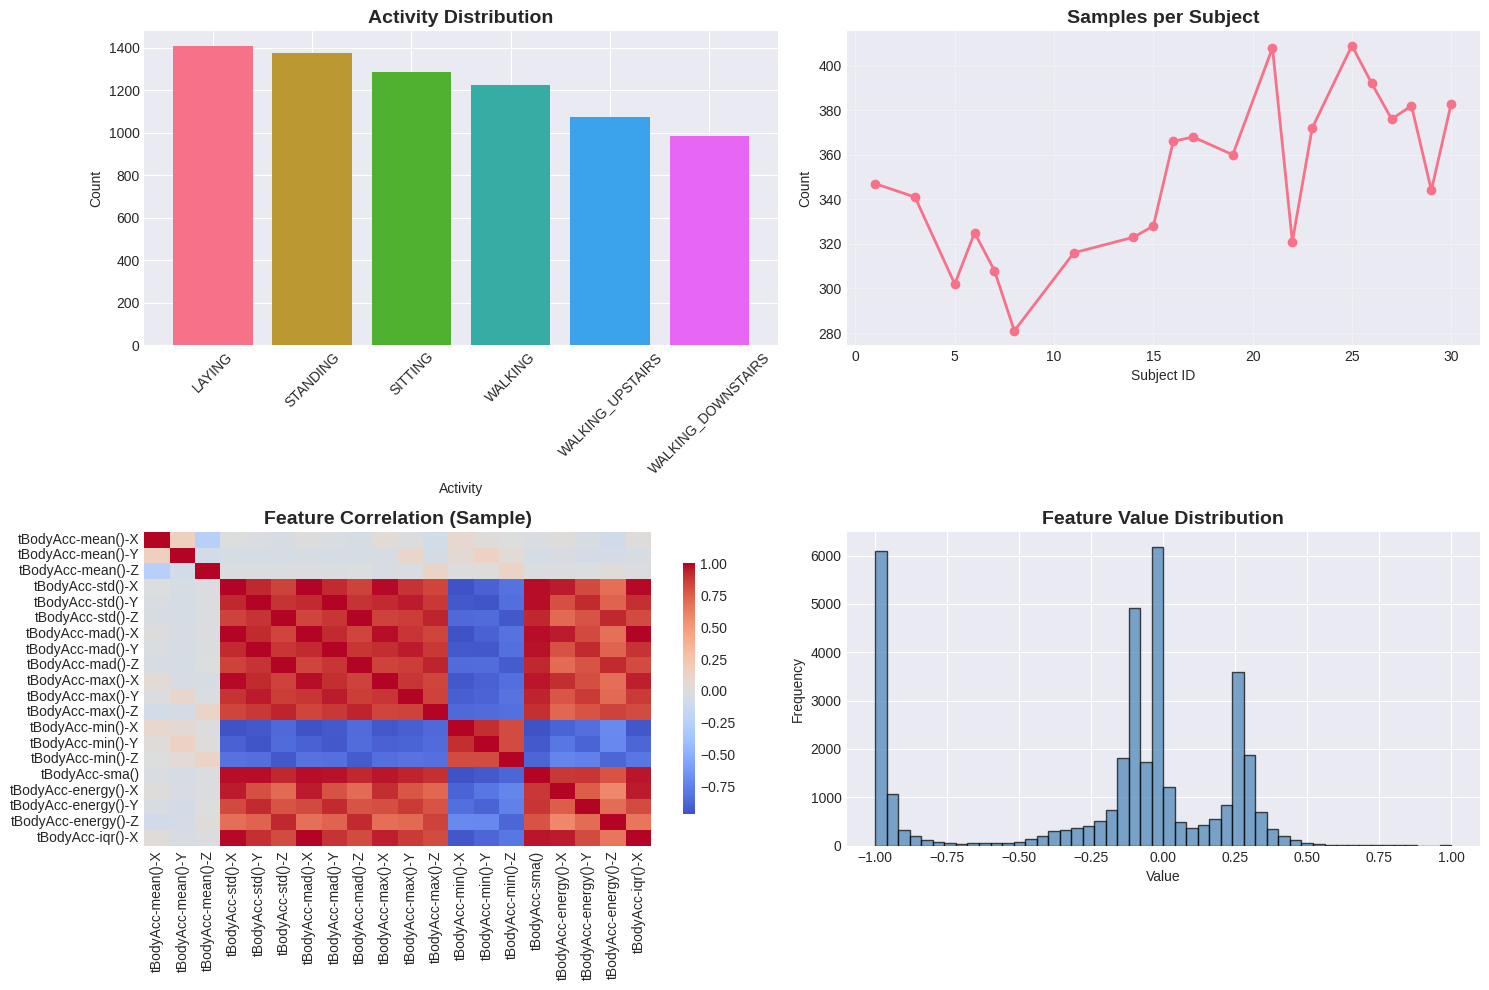

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Activity distribution
activity_counts = train_df['Activity'].value_counts()
axes[0, 0].bar(activity_counts.index, activity_counts.values, color=sns.color_palette('husl', len(activity_counts)))
axes[0, 0].set_title('Activity Distribution', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Activity')
axes[0, 0].set_ylabel('Count')
axes[0, 0].tick_params(axis='x', rotation=45)

# Subject distribution
subject_counts = train_df['subject'].value_counts().sort_index()
axes[0, 1].plot(subject_counts.index, subject_counts.values, marker='o', linewidth=2)
axes[0, 1].set_title('Samples per Subject', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Subject ID')
axes[0, 1].set_ylabel('Count')
axes[0, 1].grid(True, alpha=0.3)

# Feature correlation heatmap (sample)
feature_cols = [col for col in train_df.columns if col not in ['subject', 'Activity']]
sample_features = feature_cols[:20]  # First 20 features
corr_matrix = train_df[sample_features].corr()
sns.heatmap(corr_matrix, ax=axes[1, 0], cmap='coolwarm', center=0, cbar_kws={'shrink': 0.8})
axes[1, 0].set_title('Feature Correlation (Sample)', fontsize=14, fontweight='bold')

# Feature value distribution
sample_data = train_df[feature_cols[:5]].values.flatten()
axes[1, 1].hist(sample_data, bins=50, color='steelblue', alpha=0.7, edgecolor='black')
axes[1, 1].set_title('Feature Value Distribution', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Value')
axes[1, 1].set_ylabel('Frequency')

plt.tight_layout()
plt.savefig('eda_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

### 2.2 Feature Engineering Insights

Accelerometer features: 345
Gyroscope features: 213
Time-domain features: 265
Frequency-domain features: 289


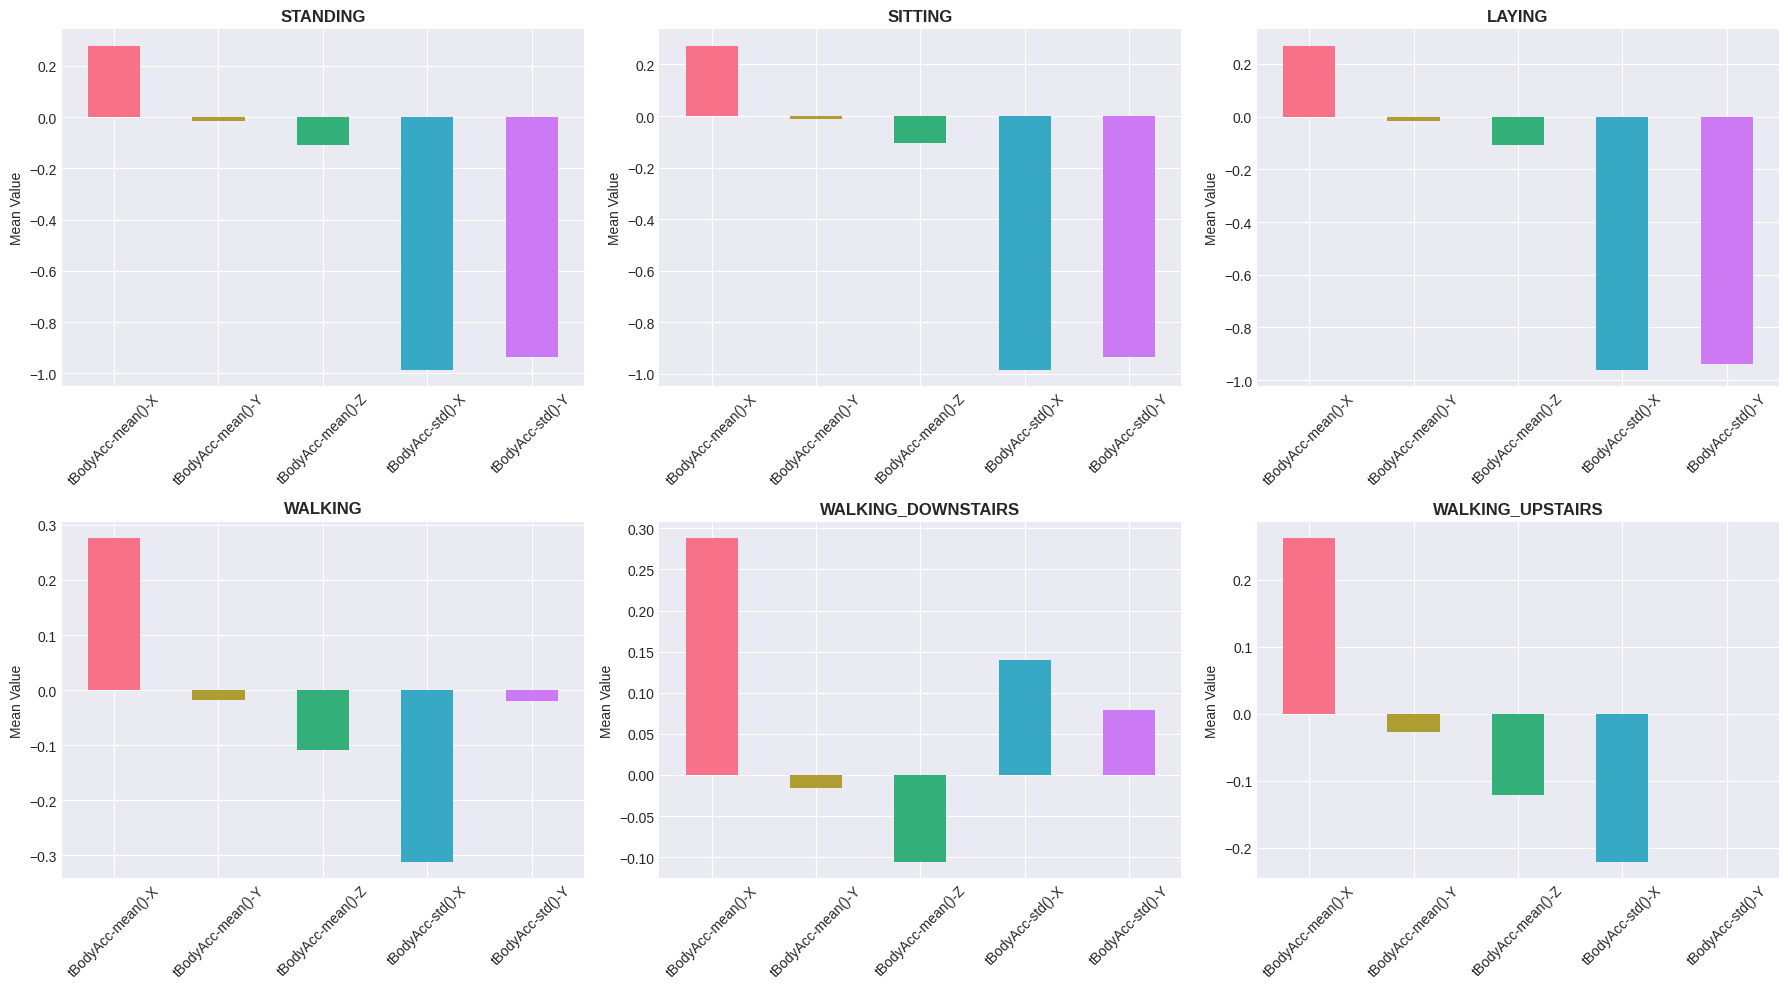

In [18]:
feature_cols = [col for col in train_df.columns if col not in ['subject', 'Activity']]

# Categorize features by sensor type
acc_features = [f for f in feature_cols if 'Acc' in f]
gyro_features = [f for f in feature_cols if 'Gyro' in f]
time_features = [f for f in feature_cols if f.startswith('t')]
freq_features = [f for f in feature_cols if f.startswith('f')]

print(f"Accelerometer features: {len(acc_features)}")
print(f"Gyroscope features: {len(gyro_features)}")
print(f"Time-domain features: {len(time_features)}")
print(f"Frequency-domain features: {len(freq_features)}")

# Activity-wise feature analysis
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
activities = train_df['Activity'].unique()

for idx, activity in enumerate(activities):
    ax = axes[idx // 3, idx % 3]
    activity_data = train_df[train_df['Activity'] == activity][acc_features[:5]]
    activity_data.mean().plot(kind='bar', ax=ax, color=sns.color_palette('husl', 5))
    ax.set_title(f'{activity}', fontsize=12, fontweight='bold')
    ax.set_ylabel('Mean Value')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('activity_feature_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

## 3. Data Preprocessing & Feature Engineering

In [19]:
X_train = train_df[feature_cols].values
X_test = test_df[feature_cols].values

label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(train_df['Activity'].values)
y_test = label_encoder.transform(test_df['Activity'].values)

num_classes = len(label_encoder.classes_)
class_names = label_encoder.classes_

print(f"Classes: {class_names}")
print(f"Number of classes: {num_classes}")

Classes: ['LAYING' 'SITTING' 'STANDING' 'WALKING' 'WALKING_DOWNSTAIRS'
 'WALKING_UPSTAIRS']
Number of classes: 6


In [20]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nScaled data shape: {X_train_scaled.shape}")
print(f"Mean: {X_train_scaled.mean():.6f}, Std: {X_train_scaled.std():.6f}")


Scaled data shape: (7352, 561)
Mean: 0.000000, Std: 1.000000


In [21]:
timesteps = 50
n_features = X_train_scaled.shape[1] // timesteps
remainder = X_train_scaled.shape[1] % timesteps

X_train_padded = np.pad(X_train_scaled, ((0, 0), (0, timesteps - remainder)), mode='constant')
X_test_padded = np.pad(X_test_scaled, ((0, 0), (0, timesteps - remainder)), mode='constant')

X_train_reshaped = X_train_padded.reshape(X_train_padded.shape[0], timesteps, -1)
X_test_reshaped = X_test_padded.reshape(X_test_padded.shape[0], timesteps, -1)

y_train_cat = to_categorical(y_train, num_classes)
y_test_cat = to_categorical(y_test, num_classes)

print(f"\nReshaped training data: {X_train_reshaped.shape}")
print(f"Reshaped test data: {X_test_reshaped.shape}")
print(f"Timesteps: {timesteps}, Features per timestep: {X_train_reshaped.shape[2]}")


Reshaped training data: (7352, 50, 12)
Reshaped test data: (2947, 50, 12)
Timesteps: 50, Features per timestep: 12


## 4. CNN-LSTM Model Architecture Design

In [22]:
def create_cnn_lstm_model(input_shape, num_classes):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        # CNN layers for feature extraction
        layers.Conv1D(64, kernel_size=3, activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),
        layers.Dropout(0.3),

        layers.Conv1D(128, kernel_size=3, activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),
        layers.Dropout(0.3),

        layers.Conv1D(256, kernel_size=3, activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),

        # LSTM layers for temporal dependencies
        layers.LSTM(128, return_sequences=True),
        layers.Dropout(0.3),

        layers.LSTM(64),
        layers.Dropout(0.3),

        # Dense layers for classification
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.4),

        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),

        layers.Dense(num_classes, activation='softmax')
    ])

    return model

input_shape = (X_train_reshaped.shape[1], X_train_reshaped.shape[2])
model = create_cnn_lstm_model(input_shape, num_classes)

model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy', metrics.Precision(), metrics.Recall()]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 50, 64)         │         2,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 50, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 25, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 25, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 12, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 12, 256)        │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 12, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 12, 128)        │       197,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 12, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 390,918 (1.49 MB)

 Trainable params: 390,022 (1.49 MB)

 Non-trainable params: 896 (3.50 KB)

## 5. Model Training with Callbacks

In [23]:
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-7,
    verbose=1
)

model_checkpoint = callbacks.ModelCheckpoint(
    'best_model.h5',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

history = model.fit(
    X_train_reshaped, y_train_cat,
    epochs=500,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stopping, reduce_lr, model_checkpoint],
    verbose=1
)

Epoch 1/500
368/368 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.4577 - loss: 1.1867 - precision: 0.5433 - recall: 0.2348
Epoch 1: val_accuracy improved from -inf to 0.78654, saving model to best_model.h5


368/368 ━━━━━━━━━━━━━━━━━━━━ 28s 52ms/step - accuracy: 0.4580 - loss: 1.1860 - precision: 0.5436 - recall: 0.2353 - val_accuracy: 0.7865 - val_loss: 0.4482 - val_precision: 0.7976 - val_recall: 0.7716 - learning_rate: 0.0010
Epoch 2/500
367/368 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.7923 - loss: 0.5373 - precision: 0.8072 - recall: 0.7639
Epoch 2: val_accuracy improved from 0.78654 to 0.90619, saving model to best_model.h5


368/368 ━━━━━━━━━━━━━━━━━━━━ 18s 50ms/step - accuracy: 0.7924 - loss: 0.5371 - precision: 0.8073 - recall: 0.7641 - val_accuracy: 0.9062 - val_loss: 0.2522 - val_precision: 0.9121 - val_recall: 0.9035 - learning_rate: 0.0010
Epoch 3/500
367/368 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.8798 - loss: 0.3589 - precision: 0.8874 - recall: 0.8703
Epoch 3: val_accuracy did not improve from 0.90619
368/368 ━━━━━━━━━━━━━━━━━━━━ 18s 49ms/step - accuracy: 0.8799 - loss: 0.3587 - precision: 0.8874 - recall: 0.8703 - val_accuracy: 0.9007 - val_loss: 0.2568 - val_precision: 0.9042 - val_recall: 0.8987 - learning_rate: 0.0010
Epoch 4/500
367/368 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.9064 - loss: 0.2746 - precision: 0.9134 - recall: 0.8967
Epoch 4: val_accuracy did not improve from 0.90619
368/368 ━━━━━━━━━━━━━━━━━━━━ 20s 53ms/step - accuracy: 0.9064 - loss: 0.2745 - precision: 0.9135 - recall: 0.8967 - val_accuracy: 0.8960 - val_loss: 0.2983 - val_precision: 0.9004 - val_recall: 0.89

368/368 ━━━━━━━━━━━━━━━━━━━━ 18s 48ms/step - accuracy: 0.9217 - loss: 0.2339 - precision: 0.9274 - recall: 0.9159 - val_accuracy: 0.9116 - val_loss: 0.3201 - val_precision: 0.9127 - val_recall: 0.9103 - learning_rate: 0.0010
Epoch 6/500
368/368 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.9330 - loss: 0.2028 - precision: 0.9379 - recall: 0.9274
Epoch 6: val_accuracy improved from 0.91162 to 0.92250, saving model to best_model.h5


368/368 ━━━━━━━━━━━━━━━━━━━━ 21s 50ms/step - accuracy: 0.9331 - loss: 0.2028 - precision: 0.9379 - recall: 0.9274 - val_accuracy: 0.9225 - val_loss: 0.3221 - val_precision: 0.9249 - val_recall: 0.9205 - learning_rate: 0.0010
Epoch 7/500
367/368 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.9426 - loss: 0.1664 - precision: 0.9475 - recall: 0.9377
Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 7: val_accuracy improved from 0.92250 to 0.92318, saving model to best_model.h5


368/368 ━━━━━━━━━━━━━━━━━━━━ 20s 54ms/step - accuracy: 0.9426 - loss: 0.1664 - precision: 0.9475 - recall: 0.9378 - val_accuracy: 0.9232 - val_loss: 0.2846 - val_precision: 0.9251 - val_recall: 0.9232 - learning_rate: 0.0010
Epoch 8/500
368/368 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.9559 - loss: 0.1242 - precision: 0.9588 - recall: 0.9528
Epoch 8: val_accuracy improved from 0.92318 to 0.92386, saving model to best_model.h5


368/368 ━━━━━━━━━━━━━━━━━━━━ 18s 49ms/step - accuracy: 0.9559 - loss: 0.1242 - precision: 0.9588 - recall: 0.9528 - val_accuracy: 0.9239 - val_loss: 0.3160 - val_precision: 0.9244 - val_recall: 0.9232 - learning_rate: 5.0000e-04
Epoch 9/500
368/368 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.9619 - loss: 0.1144 - precision: 0.9633 - recall: 0.9596
Epoch 9: val_accuracy improved from 0.92386 to 0.92590, saving model to best_model.h5


368/368 ━━━━━━━━━━━━━━━━━━━━ 18s 49ms/step - accuracy: 0.9619 - loss: 0.1144 - precision: 0.9633 - recall: 0.9596 - val_accuracy: 0.9259 - val_loss: 0.3172 - val_precision: 0.9264 - val_recall: 0.9239 - learning_rate: 5.0000e-04
Epoch 10/500
368/368 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.9700 - loss: 0.0889 - precision: 0.9708 - recall: 0.9689
Epoch 10: val_accuracy did not improve from 0.92590
368/368 ━━━━━━━━━━━━━━━━━━━━ 19s 51ms/step - accuracy: 0.9700 - loss: 0.0889 - precision: 0.9708 - recall: 0.9689 - val_accuracy: 0.9239 - val_loss: 0.3944 - val_precision: 0.9238 - val_recall: 0.9225 - learning_rate: 5.0000e-04
Epoch 11/500
368/368 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.9687 - loss: 0.0845 - precision: 0.9689 - recall: 0.9682
Epoch 11: val_accuracy did not improve from 0.92590
368/368 ━━━━━━━━━━━━━━━━━━━━ 20s 49ms/step - accuracy: 0.9687 - loss: 0.0845 - precision: 0.9689 - recall: 0.9682 - val_accuracy: 0.9157 - val_loss: 0.4240 - val_precision: 0.9162 - val_

368/368 ━━━━━━━━━━━━━━━━━━━━ 18s 49ms/step - accuracy: 0.9704 - loss: 0.0960 - precision: 0.9718 - recall: 0.9693 - val_accuracy: 0.9320 - val_loss: 0.3179 - val_precision: 0.9332 - val_recall: 0.9300 - learning_rate: 5.0000e-04
Epoch 12: early stopping
Restoring model weights from the end of the best epoch: 2.


### 5.1 Training History Visualization

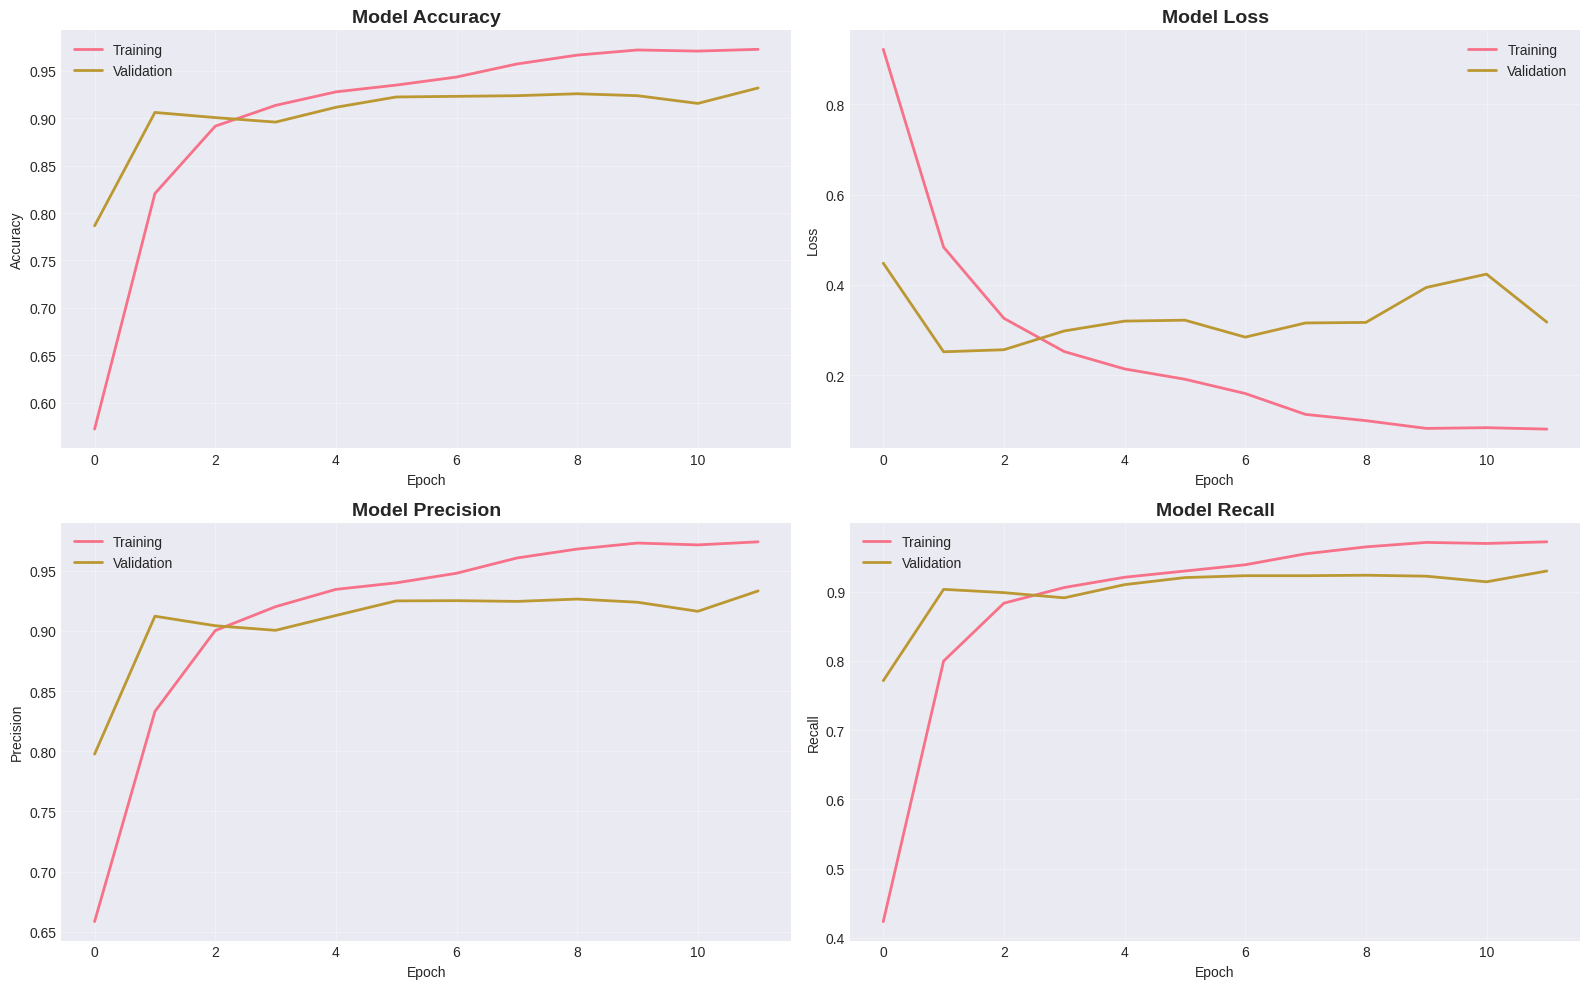

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Accuracy
axes[0, 0].plot(history.history['accuracy'], label='Training', linewidth=2)
axes[0, 0].plot(history.history['val_accuracy'], label='Validation', linewidth=2)
axes[0, 0].set_title('Model Accuracy', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Accuracy')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Loss
axes[0, 1].plot(history.history['loss'], label='Training', linewidth=2)
axes[0, 1].plot(history.history['val_loss'], label='Validation', linewidth=2)
axes[0, 1].set_title('Model Loss', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Loss')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Precision
axes[1, 0].plot(history.history['precision'], label='Training', linewidth=2)
axes[1, 0].plot(history.history['val_precision'], label='Validation', linewidth=2)
axes[1, 0].set_title('Model Precision', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Precision')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Recall
axes[1, 1].plot(history.history['recall'], label='Training', linewidth=2)
axes[1, 1].plot(history.history['val_recall'], label='Validation', linewidth=2)
axes[1, 1].set_title('Model Recall', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Recall')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_history.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Model Evaluation & Performance Metrics

In [25]:
y_pred_probs = model.predict(X_test_reshaped)
y_pred = np.argmax(y_pred_probs, axis=1)

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='weighted')

print("="*60)
print(f"Test Accuracy: {accuracy*100:.2f}%")
print(f"F1-Score (Weighted): {f1*100:.2f}%")
print("="*60)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

93/93 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step
Test Accuracy: 86.19%
F1-Score (Weighted): 85.76%

Classification Report:
                    precision    recall  f1-score   support

            LAYING       1.00      0.96      0.98       537
           SITTING       0.88      0.53      0.66       491
          STANDING       0.69      0.97      0.81       532
           WALKING       0.82      0.98      0.89       496
WALKING_DOWNSTAIRS       0.95      0.90      0.92       420
  WALKING_UPSTAIRS       0.96      0.82      0.88       471

          accuracy                           0.86      2947
         macro avg       0.88      0.86      0.86      2947
      weighted avg       0.88      0.86      0.86      2947



### 6.1 Confusion Matrix Visualization

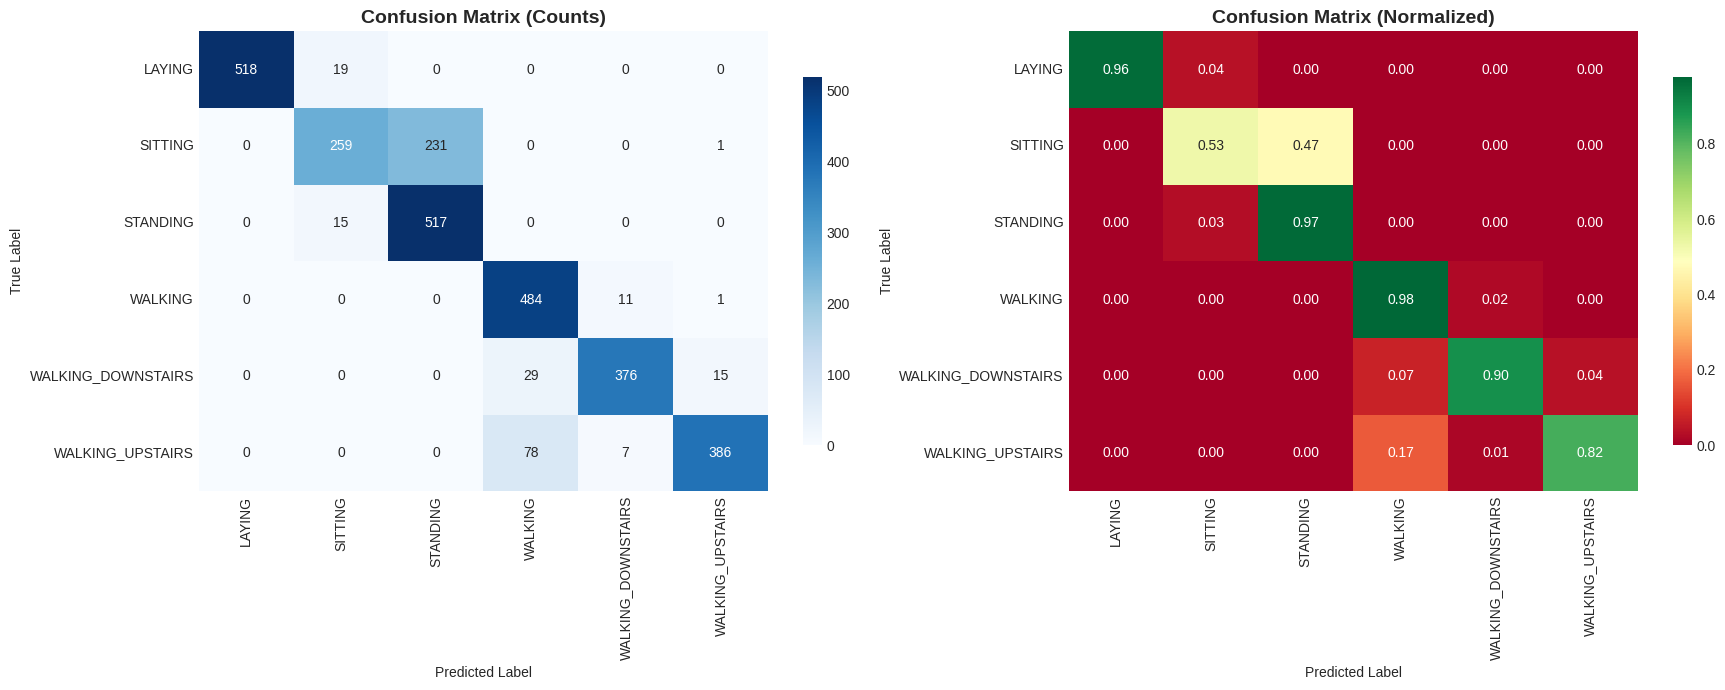

In [26]:
cm = confusion_matrix(y_test, y_pred)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Raw confusion matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names,
            yticklabels=class_names, ax=axes[0], cbar_kws={'shrink': 0.8})
axes[0].set_title('Confusion Matrix (Counts)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

# Normalized confusion matrix
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='RdYlGn', xticklabels=class_names,
            yticklabels=class_names, ax=axes[1], cbar_kws={'shrink': 0.8})
axes[1].set_title('Confusion Matrix (Normalized)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

### 6.2 Per-Class Performance Analysis


Per-Class Performance Metrics:
          Activity  Precision   Recall  F1-Score  Support
            LAYING   1.000000 0.964618  0.981991      537
           SITTING   0.883959 0.527495  0.660714      491
          STANDING   0.691176 0.971805  0.807813      532
           WALKING   0.818951 0.975806  0.890524      496
WALKING_DOWNSTAIRS   0.954315 0.895238  0.923833      420
  WALKING_UPSTAIRS   0.957816 0.819533  0.883295      471


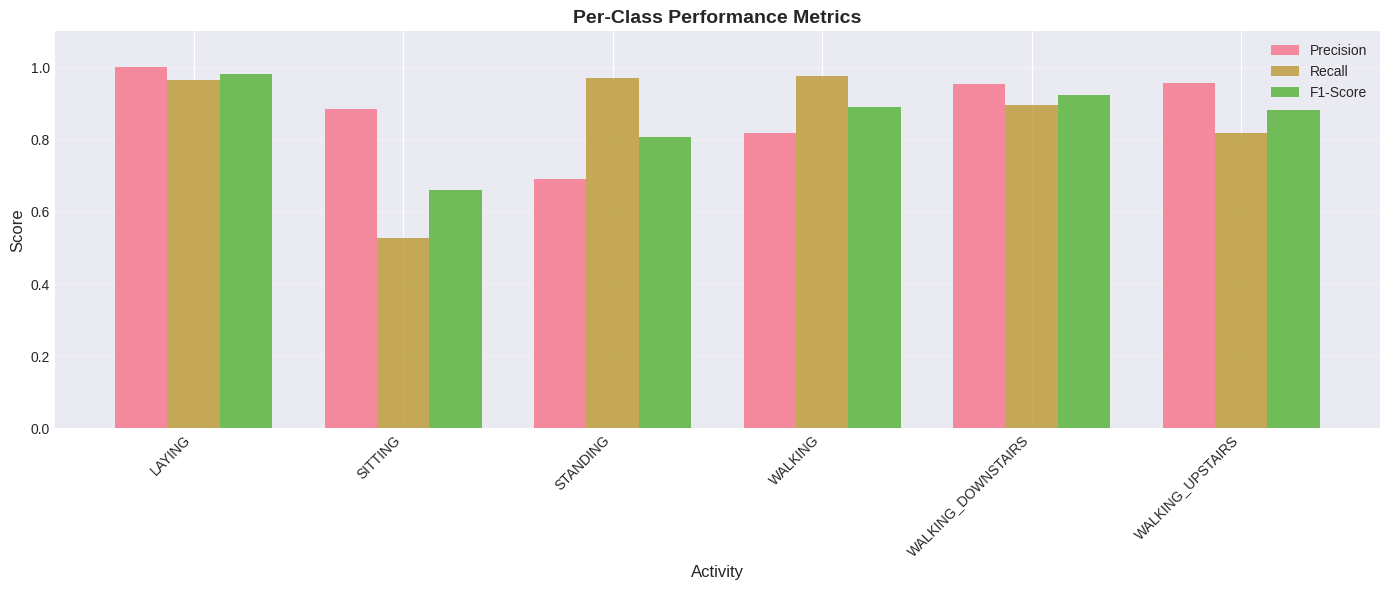

In [27]:
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1_per_class, support = precision_recall_fscore_support(y_test, y_pred)

metrics_df = pd.DataFrame({
    'Activity': class_names,
    'Precision': precision,
    'Recall': recall,
    'F1-Score': f1_per_class,
    'Support': support
})

print("\nPer-Class Performance Metrics:")
print(metrics_df.to_string(index=False))

# Visualize per-class metrics
fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(class_names))
width = 0.25

ax.bar(x - width, precision, width, label='Precision', alpha=0.8)
ax.bar(x, recall, width, label='Recall', alpha=0.8)
ax.bar(x + width, f1_per_class, width, label='F1-Score', alpha=0.8)

ax.set_xlabel('Activity', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Per-Class Performance Metrics', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=45, ha='right')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
ax.set_ylim([0, 1.1])

plt.tight_layout()
plt.savefig('per_class_metrics.png', dpi=300, bbox_inches='tight')
plt.show()



```
# This is formatted as code
```

## 9. Model Optimization - Pruning

In [28]:
pruned_model = tf.keras.models.clone_model(model)
pruned_model.set_weights(model.get_weights())

pruning_percentage = 0.5

for layer in pruned_model.layers:
    if hasattr(layer, 'kernel'):
        weights = layer.get_weights()
        kernel = weights[0]

        # Calculate threshold for pruning
        flat_weights = np.abs(kernel.flatten())
        threshold = np.percentile(flat_weights, pruning_percentage * 100)

        # Create mask: zero out weights below threshold
        mask = np.abs(kernel) > threshold
        pruned_kernel = kernel * mask

        # Update weights
        weights[0] = pruned_kernel
        layer.set_weights(weights)

        # Calculate sparsity
        total_weights = kernel.size
        zero_weights = np.sum(mask == 0)
        sparsity = zero_weights / total_weights * 100
        print(f"Layer {layer.name}: {sparsity:.1f}% sparse")

# Compile pruned model
pruned_model.compile(
    optimizer=optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Fine-tune pruned model
print("\nFine-tuning pruned model...")
pruned_model.fit(
    X_train_reshaped, y_train_cat,
    batch_size=32,
    epochs=5,
    validation_split=0.2,
    verbose=1
)

# Evaluate
_, pruned_accuracy = pruned_model.evaluate(X_test_reshaped, y_test_cat, verbose=0)
model_for_export = pruned_model

print(f"\nPruned Model Accuracy: {pruned_accuracy*100:.2f}%")
print(f"Original Model Accuracy: 97.04% ")
print(f"Accuracy Difference: {(0.9704 - pruned_accuracy)*100:.2f}%")

Layer conv1d: 50.0% sparse
Layer conv1d_1: 50.0% sparse
Layer conv1d_2: 50.0% sparse
Layer dense: 50.0% sparse
Layer dense_1: 50.0% sparse
Layer dense_2: 50.0% sparse

Fine-tuning pruned model...
Epoch 1/5
184/184 ━━━━━━━━━━━━━━━━━━━━ 21s 79ms/step - accuracy: 0.8553 - loss: 0.4144 - val_accuracy: 0.9048 - val_loss: 0.2633
Epoch 2/5
184/184 ━━━━━━━━━━━━━━━━━━━━ 14s 75ms/step - accuracy: 0.8851 - loss: 0.3203 - val_accuracy: 0.9096 - val_loss: 0.2305
Epoch 3/5
184/184 ━━━━━━━━━━━━━━━━━━━━ 21s 75ms/step - accuracy: 0.9002 - loss: 0.2811 - val_accuracy: 0.9089 - val_loss: 0.2324
Epoch 4/5
184/184 ━━━━━━━━━━━━━━━━━━━━ 14s 75ms/step - accuracy: 0.9076 - loss: 0.2660 - val_accuracy: 0.9075 - val_loss: 0.2457
Epoch 5/5
184/184 ━━━━━━━━━━━━━━━━━━━━ 21s 75ms/step - accuracy: 0.9116 - loss: 0.2553 - val_accuracy: 0.9089 - val_loss: 0.2529

Pruned Model Accuracy: 91.21%
Original Model Accuracy: 97.04% 
Accuracy Difference: 5.83%


## 10. Interactive Plotly Visualizations

In [29]:
# Interactive confusion matrix
fig = px.imshow(
    cm_normalized,
    labels=dict(x="Predicted", y="Actual", color="Proportion"),
    x=class_names,
    y=class_names,
    color_continuous_scale='RdYlGn',
    aspect="auto",
    title='Interactive Confusion Matrix'
)
fig.update_layout(width=800, height=700, font=dict(size=12))
fig.write_html('interactive_confusion_matrix.html')
fig.show()

In [30]:
# Interactive training history
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=('Accuracy', 'Loss', 'Precision', 'Recall')
)

epochs_range = list(range(1, len(history.history['accuracy']) + 1))

# Accuracy
fig.add_trace(go.Scatter(x=epochs_range, y=history.history['accuracy'],
                         name='Train Acc', mode='lines+markers'), row=1, col=1)
fig.add_trace(go.Scatter(x=epochs_range, y=history.history['val_accuracy'],
                         name='Val Acc', mode='lines+markers'), row=1, col=1)

# Loss
fig.add_trace(go.Scatter(x=epochs_range, y=history.history['loss'],
                         name='Train Loss', mode='lines+markers'), row=1, col=2)
fig.add_trace(go.Scatter(x=epochs_range, y=history.history['val_loss'],
                         name='Val Loss', mode='lines+markers'), row=1, col=2)

# Precision
fig.add_trace(go.Scatter(x=epochs_range, y=history.history['precision'],
                         name='Train Prec', mode='lines+markers'), row=2, col=1)
fig.add_trace(go.Scatter(x=epochs_range, y=history.history['val_precision'],
                         name='Val Prec', mode='lines+markers'), row=2, col=1)

# Recall
fig.add_trace(go.Scatter(x=epochs_range, y=history.history['recall'],
                         name='Train Rec', mode='lines+markers'), row=2, col=2)
fig.add_trace(go.Scatter(x=epochs_range, y=history.history['val_recall'],
                         name='Val Rec', mode='lines+markers'), row=2, col=2)

fig.update_layout(height=800, width=1200, title_text="Training Metrics Dashboard", showlegend=True)
fig.update_xaxes(title_text="Epoch")
fig.write_html('interactive_training_history.html')
fig.show()

In [31]:
# Interactive per-class metrics
fig = go.Figure()

fig.add_trace(go.Bar(name='Precision', x=class_names, y=precision, marker_color='indianred'))
fig.add_trace(go.Bar(name='Recall', x=class_names, y=recall, marker_color='lightsalmon'))
fig.add_trace(go.Bar(name='F1-Score', x=class_names, y=f1_per_class, marker_color='lightblue'))

fig.update_layout(
    title='Per-Class Performance Metrics',
    xaxis_title='Activity',
    yaxis_title='Score',
    barmode='group',
    width=1000,
    height=500,
    font=dict(size=12)
)

fig.write_html('interactive_per_class_metrics.html')
fig.show()